# 03. Когорты, retention и LTV

Возвращаются ли клиенты после первой покупки, как быстро и сколько приносят за жизнь.

**Когорта** - месяц первой *покупки* (заказ в статусе с выручкой). **Retention месяца N** - доля когорты, совершившая покупку в N-м месяце после месяца когорты.

**Данные:** `marts.mart_cohort_retention`, `marts.fct_orders`. В витрине нет строк для месяцев, которые когорта ещё не прожила, - это не ноль, а «неизвестно». Месяц даты среза (последний заказ в данных) наблюдается не целиком и помечен `is_complete_period = false`.

In [1]:
import sys
sys.path.insert(0, "..")  # модуль analytics лежит в корне репозитория

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from analytics.db import query
from analytics.plots import setup, money_axis, percent_axis, BLUE, ORANGE, AQUA, YELLOW, GRAY, SERIES

setup()
pd.set_option("display.float_format", "{:,.2f}".format)

from scipy import stats
from statsmodels.stats.proportion import proportion_confint
from statsmodels.duration.survfunc import SurvfuncRight

In [2]:
ret = query("select * from mart_cohort_retention order by cohort_month, month_offset")
sizes = ret.groupby("cohort_month").cohort_size.first()
print(sizes.to_string())

MIN_COHORT = 100
small = sizes[sizes < MIN_COHORT]
ret = ret[ret.cohort_month.isin(sizes[sizes >= MIN_COHORT].index)]
if len(small):
    print(f"\nИсключены когорты меньше {MIN_COHORT} клиентов (данные начинаются в конце месяца): "
          f"{', '.join(f'{d:%Y-%m}' for d in small.index)}")

cohort_month
2026-05-01     666
2026-06-01     817
2026-07-01     904
2026-08-01    1053
2026-09-01    1152
2026-10-01    1184


## Тепловая карта retention

Цвет считается по месяцам 1+ (месяц 0 по определению равен 100% и съел бы всю шкалу). Звёздочкой отмечен месяц даты среза, который наблюдается не целиком: при новых данных его значение вырастет. Пустые ячейки - месяцы, которых когорта ещё не прожила.

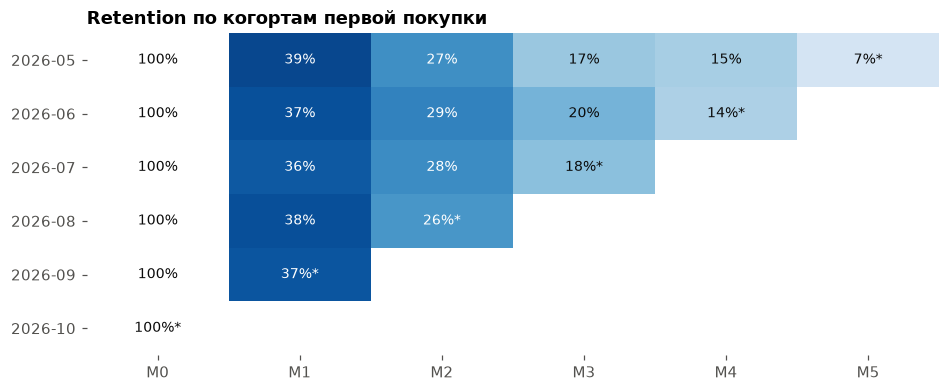

In [3]:
pivot = ret.pivot(index="cohort_month", columns="month_offset", values="retention_rate")
incomplete = ret.pivot(index="cohort_month", columns="month_offset", values="is_complete_period") == 0

fig, ax = plt.subplots(figsize=(10, 3.8))
shown = pivot.copy()
shown[0] = np.nan
im = ax.imshow(shown.values, cmap="Blues", vmin=0, vmax=np.nanmax(shown.values) * 1.1, aspect="auto")
for i in range(pivot.shape[0]):
    for j in range(pivot.shape[1]):
        v = pivot.iat[i, j]
        if np.isnan(v):
            continue
        star = "*" if incomplete.iat[i, j] else ""
        dark = j > 0 and v > np.nanmax(shown.values) * 0.6
        ax.text(j, i, f"{v:.0%}{star}", ha="center", va="center", fontsize=9,
                color="white" if dark else "#0b0b0b")
ax.set_xticks(range(pivot.shape[1]), [f"M{c}" for c in pivot.columns])
ax.set_yticks(range(pivot.shape[0]), [f"{d:%Y-%m}" for d in pivot.index])
ax.set_title("Retention по когортам первой покупки")
ax.grid(False)
for spine in ax.spines.values():
    spine.set_visible(False)
plt.show()

## Средняя кривая удержания

Среднее по когортам - взвешенное по размеру когорты и только по завершённым месяцам: `sum(вернувшихся) / sum(размеров)` для когорт, которые этот месяц уже прожили. Простое среднее процентов дало бы маленькой когорте тот же вес, что большой, а нули вместо «неизвестно» занизили бы дальние месяцы.

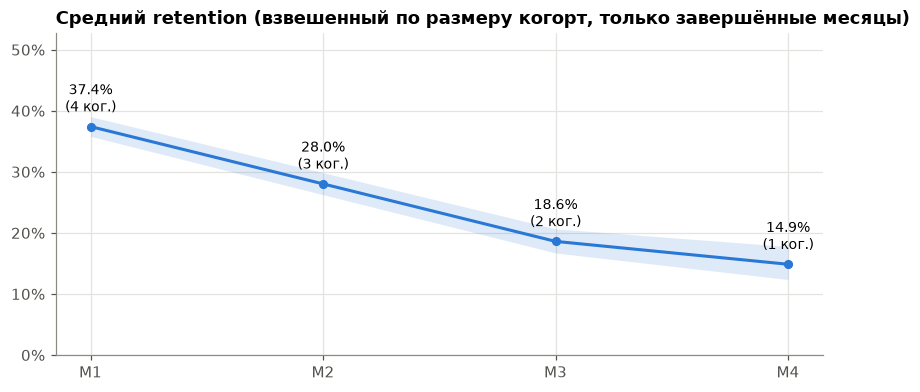

,cohorts,size,active,retention,lo,hi
month_offset,,,,,,
1,4,"3,440","1,287",37.4%,35.8%,39.0%
2,3,"2,387",669,28.0%,26.3%,29.9%
3,2,"1,483",276,18.6%,16.7%,20.7%
4,1,666,99,14.9%,12.4%,17.8%


In [4]:
complete = ret[ret.is_complete_period == 1]
curve = complete.groupby("month_offset").agg(active=("active_customers", "sum"),
                                             size=("cohort_size", "sum"),
                                             cohorts=("cohort_month", "nunique"))
curve["retention"] = curve.active / curve["size"]
curve["lo"], curve["hi"] = proportion_confint(curve.active, curve["size"], method="wilson")
curve = curve[curve.index > 0]

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.fill_between(curve.index, curve.lo, curve.hi, color=BLUE, alpha=0.15, linewidth=0)
ax.plot(curve.index, curve.retention, color=BLUE, marker="o", markersize=5)
for x, row in curve.iterrows():
    ax.annotate(f"{row.retention:.1%}\n({row.cohorts:.0f} ког.)", (x, row.retention), xytext=(0, 10),
                textcoords="offset points", ha="center", fontsize=9)
percent_axis(ax)
ax.set_xticks(curve.index, [f"M{c}" for c in curve.index])
ax.set_ylim(0, curve.hi.max() * 1.35)
ax.set_title("Средний retention (взвешенный по размеру когорт, только завершённые месяцы)")
plt.show()
curve[["cohorts", "size", "active", "retention", "lo", "hi"]].style.format(
    {"size": "{:,.0f}", "active": "{:,.0f}", "retention": "{:.1%}", "lo": "{:.1%}", "hi": "{:.1%}"})

## Стабилен ли retention между когортами

Если продукт или маркетинг меняются, у новых когорт retention будет другим. Проверяем однородность retention месяца 1 по когортам хи-квадрат тестом (H0: доля вернувшихся в M1 одинакова у всех когорт).

In [5]:
m1 = complete[complete.month_offset == 1]
table = np.column_stack([m1.active_customers, m1.cohort_size - m1.active_customers])
chi2, p_value, dof, _ = stats.chi2_contingency(table)
display(m1[["cohort_month", "cohort_size", "active_customers", "retention_rate"]]
        .style.format({"cohort_month": "{:%Y-%m}", "retention_rate": "{:.1%}"}).hide(axis="index"))
print(f"chi2 = {chi2:.2f}, df = {dof}, p-value = {p_value:.3f}")

cohort_month,cohort_size,active_customers,retention_rate
2026-05,666,259,38.9%
2026-06,817,306,37.5%
2026-07,904,326,36.1%
2026-08,1053,396,37.6%


chi2 = 1.34, df = 3, p-value = 0.719


## Накопленная выручка на клиента (LTV)

Сколько в среднем приносит клиент когорты к концу месяца N (включая первую покупку). Только завершённые месяцы. Цвет когорты - от светлого (старые) к тёмному (новые).

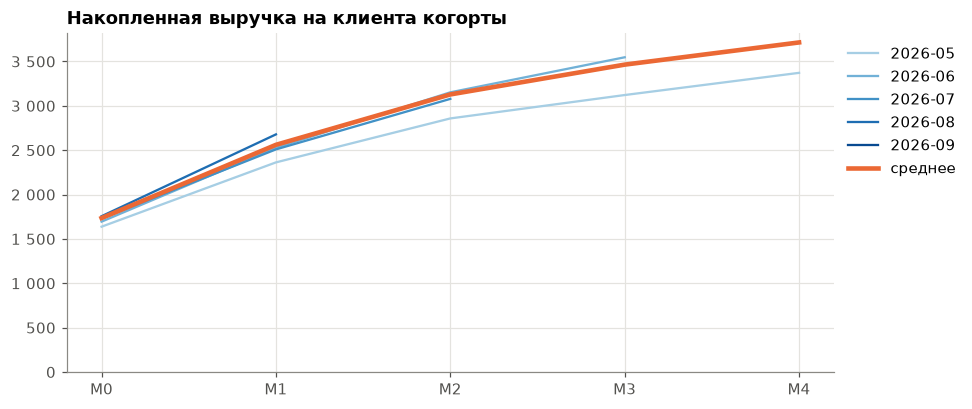

,LTV,Прирост за месяц
month_offset,,
0,"1,735","1,735"
1,"2,561",825
2,"3,128",568
3,"3,464",336
4,"3,714",250


In [6]:
ltv = complete.sort_values(["cohort_month", "month_offset"]).copy()
ltv["ltv"] = ltv.groupby("cohort_month").revenue.cumsum() / ltv.cohort_size

avg = ltv.groupby("month_offset").agg(revenue=("revenue", "sum"), size=("cohort_size", "sum"))
avg_ltv = (avg.revenue / avg["size"]).cumsum()  # средний прирост за месяц, накопленный

cohorts = sorted(ltv.cohort_month.unique())
shades = plt.get_cmap("Blues")(np.linspace(0.35, 0.9, len(cohorts)))

fig, ax = plt.subplots(figsize=(9, 4))
for cohort, color in zip(cohorts, shades):
    c = ltv[ltv.cohort_month == cohort]
    ax.plot(c.month_offset, c.ltv, color=color, linewidth=1.5, label=f"{pd.Timestamp(cohort):%Y-%m}")
ax.plot(avg_ltv.index, avg_ltv.values, color=ORANGE, linewidth=3, label="среднее")
ax.set_xticks(avg_ltv.index, [f"M{c}" for c in avg_ltv.index])
money_axis(ax)
ax.set_ylim(bottom=0)
ax.set_title("Накопленная выручка на клиента когорты")
ax.legend(loc="upper left", bbox_to_anchor=(1, 1))
plt.show()
pd.DataFrame({"LTV": avg_ltv, "Прирост за месяц": avg_ltv.diff().fillna(avg_ltv)}).style.format("{:,.0f}")

## Время до второй покупки

Доля клиентов, «сделавших вторую покупку к дню t», тоже страдает от цензурирования: клиент, купивший впервые неделю назад, ещё не мог вернуться через 60 дней. Наивная доля («вернулись / все») занижена. Корректная оценка - кривая Каплана-Мейера: клиенты без второй покупки участвуют в расчёте, пока за ними есть наблюдение, а потом выбывают как цензурированные.

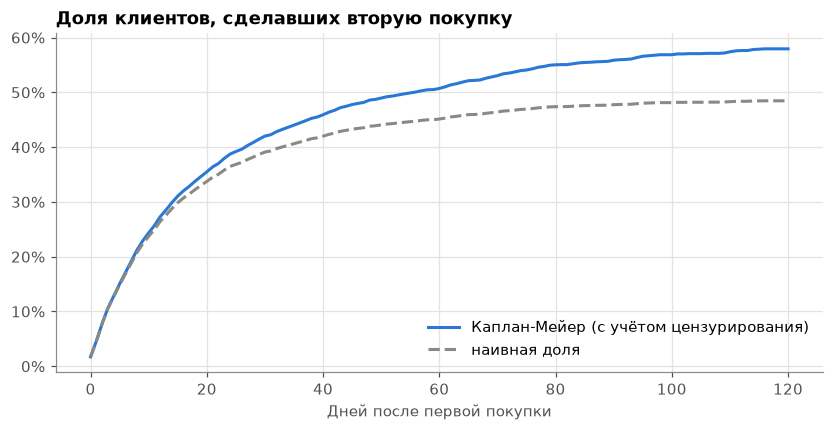

,Каплан-Мейер,Наивная доля
30 дней,42.0%,39.1%
60 дней,50.7%,45.1%
90 дней,55.9%,47.7%
120 дней,57.9%,48.5%


Медиана дней до второй покупки среди вернувшихся: 11


In [7]:
purchases = query("""
    select customer_id, order_date
    from fct_orders
    where is_revenue
    order by customer_id, created_at
""")
data_end = purchases.order_date.max()
first = purchases.groupby("customer_id").order_date.min()
nth = purchases.groupby("customer_id").cumcount()
second = purchases[nth == 1].set_index("customer_id").order_date.reindex(first.index)

returned = second.notna()
# событие "вторая покупка": для вернувшихся - время до неё, для остальных - время наблюдения (цензура)
duration = np.where(returned, (second - first).dt.days, (data_end - first).dt.days)
km = SurvfuncRight(duration, returned.astype(int).values)

t = np.arange(0, 121)
idx = np.searchsorted(km.surv_times, t, side="right") - 1
km_share = 1 - np.where(idx >= 0, km.surv_prob[np.clip(idx, 0, None)], 1.0)
naive = [(returned & (duration <= x)).mean() for x in t]

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(t, km_share, color=BLUE, label="Каплан-Мейер (с учётом цензурирования)")
ax.plot(t, naive, color=GRAY, linestyle="--", label="наивная доля")
percent_axis(ax)
ax.set_xlabel("Дней после первой покупки")
ax.set_title("Доля клиентов, сделавших вторую покупку")
ax.legend(loc="lower right")
plt.show()

marks = pd.DataFrame({"Каплан-Мейер": km_share[[30, 60, 90, 120]], "Наивная доля": np.array(naive)[[30, 60, 90, 120]]},
                     index=["30 дней", "60 дней", "90 дней", "120 дней"])
display(marks.style.format("{:.1%}"))
print(f"Медиана дней до второй покупки среди вернувшихся: {np.median(duration[returned]):.0f}")

## Выводы

*Данные синтетические (`backfill.py`, seed 42): цифры описывают модель магазина, а ценность ноутбука - в методике.*

1. **Удержание:** в следующем месяце после первой покупки возвращаются 37.4% клиентов (95% ДИ 35.8-39.0%), через 2 месяца - 28.0%, через 3 - 18.6%, через 4 - 14.9%. Среднее взвешено по размеру когорт и считается только по завершённым месяцам.
2. **Retention стабилен между когортами:** доля вернувшихся в M1 у когорт мая-августа статистически не различается (chi2 = 1.34, p = 0.72). Качество привлечения не меняется, и средней кривой можно пользоваться для прогнозов.
3. **LTV:** клиент приносит в среднем 1 735 в месяц первой покупки и 3 714 к концу четвёртого месяца. Прирост быстро затухает (+825, +568, +336, +250): основная ценность клиента набирается в первые 2-3 месяца, поэтому главный рычаг - удержание в первый месяц.
4. **Вторая покупка.** По Каплану-Мейеру 42% клиентов возвращаются за 30 дней и 56% - за 90. Наивная доля занижает этот показатель на 8 п.п. к 90-му дню, потому что недавние клиенты ещё не успели вернуться. Медиана времени до второй покупки среди вернувшихся - 11 дней: триггерную коммуникацию (напоминание, персональная подборка) имеет смысл отправлять в первые две недели.
5. **Неполные периоды** (месяц даты среза, отмечен `*`) показаны на тепловой карте, но в средние и LTV не входят: их значения вырастут при новых данных.